# Project 2: Learning Hyperbolic Volume from the Jones Polynomial

**Question.** Project 1 showed that one value of the Jones polynomial, V(−1) = ±det(K), predicts hyperbolic
volume fairly well. Can a neural network predict volume from the *whole* Jones polynomial? And if it can, can we
open the black box and find a simple formula behind it?

**Background.** This repeats, on a smaller dataset, an experiment by Jejjala, Kar and Parrikar (2019), who found
that a small neural network predicts volume from the Jones polynomial with about 97% accuracy. It connects to the
**volume conjecture**, which relates colored Jones polynomials evaluated at roots of unity to hyperbolic volume.

**Data.** The 2,970 hyperbolic knots with up to 12 crossings in KnotInfo (`data/knots.csv`, from `load_data.py`).

**How results are measured.** *Mean relative error* = average of |predicted − true| / true. Every number below
comes from **5-fold cross-validation**: the knots are split into 5 groups, each model is trained on 4 groups and
tested on the 5th, and the 5 test errors are averaged. So every reported error is on knots the model never saw.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
warnings.filterwarnings("ignore")

ALT, NONALT, INK = "#257de0", "#f47230", "#333333"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

df = pd.read_csv("data/knots.csv")
df = df[df["hyperbolic"]].reset_index(drop=True)
coeffs = df["jones_coefficients"].str.split().apply(lambda v: np.array(v, dtype=float))
y = df["volume"].values
print(len(df), "hyperbolic knots; volume ranges from", y.min().round(2), "to", y.max().round(2))

2970 hyperbolic knots; volume ranges from 2.03 to 23.44


## 1. Turning a polynomial into numbers a model can read

Each Jones polynomial has a different length, but models need inputs of a fixed size. We use the vector
`[min_degree, max_degree, c0, c1, ..., c12]`: the lowest and highest powers of t, then the coefficients padded
with zeros to length 13 (the longest polynomial in the data).

In [2]:
L = max(len(v) for v in coeffs)
C = np.array([np.pad(v, (0, L - len(v))) for v in coeffs])
X = np.column_stack([df["jones_min_degree"], df["jones_max_degree"], C])
print("Input shape:", X.shape)
print("Example, knot", df.name[0], "V(t) =", df.jones_polynomial[0], "->", X[0].astype(int))

kfold = KFold(n_splits=5, shuffle=True, random_state=0)

def evaluate(model, features):
    """Cross-validated predictions: each knot is predicted by a model that never saw it."""
    pred = cross_val_predict(model, features, y, cv=kfold)
    return pred, np.mean(np.abs(pred - y) / y)

Input shape: (2970, 15)
Example, knot 4_1 V(t) = t^(-2)-t^(-1)+ 1-t+ t^2 -> [-2  2  1 -1  1 -1  1  0  0  0  0  0  0  0  0]


## 2. Baselines: how well do simple models do?

A neural network is only interesting if it beats simple methods. Two baselines:
- **Linear regression on log(determinant)**: the best single predictor from Project 1.
- **Linear regression on the full coefficient vector**: same input as the network, but a straight-line model.

In [3]:
log_det = np.log(df["determinant"].clip(lower=1)).values.reshape(-1, 1)
_, err_det = evaluate(LinearRegression(), log_det)
_, err_lin = evaluate(LinearRegression(), X)
print(f"Linear regression on log(det):            mean relative error = {err_det:.1%}")
print(f"Linear regression on Jones coefficients:  mean relative error = {err_lin:.1%}")

Linear regression on log(det):            mean relative error = 11.6%
Linear regression on Jones coefficients:  mean relative error = 17.1%


## 3. The neural network

A multilayer perceptron with two hidden layers of 100 neurons each, the same size used by Jejjala, Kar and Parrikar.
`StandardScaler` rescales each input to mean 0 and standard deviation 1, which helps training. `early_stopping`
holds back 10% of the training data and stops when the error on it stops improving, to avoid overfitting.

Neural network:  mean relative error = 4.5%   (accuracy about 95.5%)
   alternating knots:      4.2%
   non-alternating knots:  5.1%


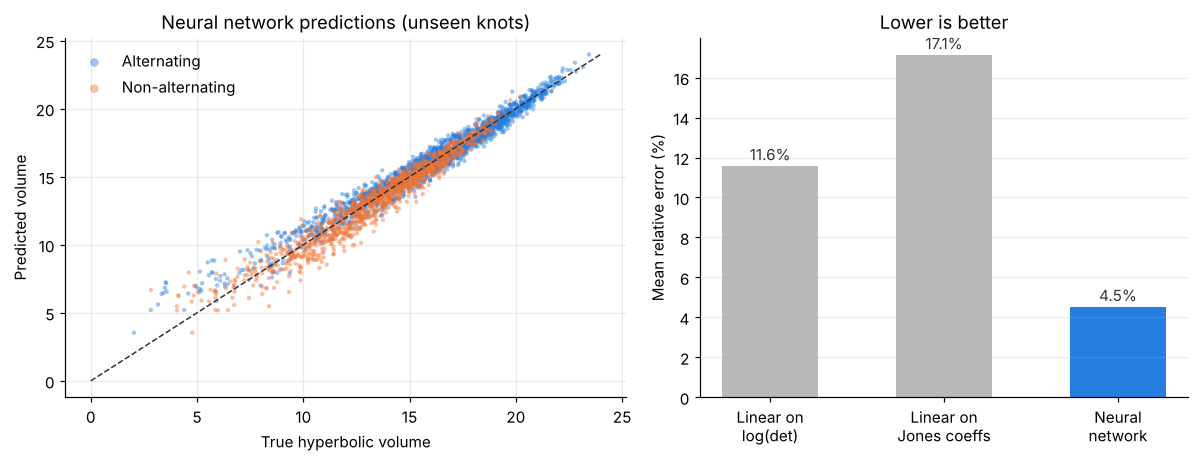

In [4]:
def make_net(seed=0):
    return make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(100, 100), max_iter=2000,
                                      early_stopping=True, random_state=seed))

pred_nn, err_nn = evaluate(make_net(), X)
alt = df["alternating"].values
print(f"Neural network:  mean relative error = {err_nn:.1%}   (accuracy about {1 - err_nn:.1%})")
print(f"   alternating knots:      {np.mean(np.abs(pred_nn - y)[alt] / y[alt]):.1%}")
print(f"   non-alternating knots:  {np.mean(np.abs(pred_nn - y)[~alt] / y[~alt]):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
for mask, col, lab in [(alt, ALT, "Alternating"), (~alt, NONALT, "Non-alternating")]:
    ax.scatter(y[mask], pred_nn[mask], s=8, alpha=0.45, color=col, edgecolor="none", label=lab)
ax.plot([0, 24], [0, 24], color=INK, lw=1, ls="--")
ax.set(xlabel="True hyperbolic volume", ylabel="Predicted volume", title="Neural network predictions (unseen knots)")
ax.legend(frameon=False, loc="upper left", markerscale=2)

ax = axes[1]
names = ["Linear on\nlog(det)", "Linear on\nJones coeffs", "Neural\nnetwork"]
errs = [err_det, err_lin, err_nn]
bars = ax.bar(names, [e * 100 for e in errs], color=["#b9b9b9", "#b9b9b9", ALT], width=0.55)
for b, e in zip(bars, errs):
    ax.text(b.get_x() + b.get_width() / 2, e * 100 + 0.3, f"{e:.1%}", ha="center", color=INK)
ax.set(ylabel="Mean relative error (%)", title="Lower is better")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("figures/p2_network_results.png", dpi=150); plt.show()

## 4. How much data does the network need?

Jejjala, Kar and Parrikar observed that the network learns from a small fraction of knots. We train on 5% to 80%
of the knots and always test on the rest.

Train on   5% ( 148 knots): test error 18.9%


Train on  10% ( 297 knots): test error 8.1%


Train on  20% ( 594 knots): test error 5.6%


Train on  40% (1188 knots): test error 5.3%


Train on  80% (2376 knots): test error 4.5%


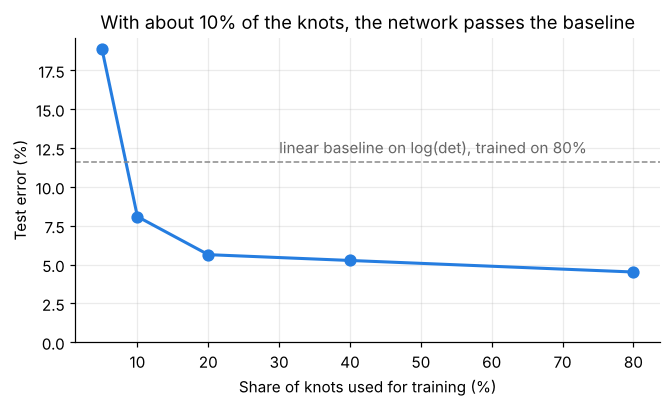

In [5]:
rng = np.random.default_rng(1)
fractions = [0.05, 0.10, 0.20, 0.40, 0.80]
curve = []
for f in fractions:
    errs_f = []
    for rep in range(3):                     # 3 random splits per fraction, then average
        idx = rng.permutation(len(y))
        n_train = int(f * len(y))
        tr, te = idx[:n_train], idx[n_train:]
        net = make_net(seed=rep).fit(X[tr], y[tr])
        errs_f.append(np.mean(np.abs(net.predict(X[te]) - y[te]) / y[te]))
    curve.append(np.mean(errs_f))
    print(f"Train on {f:>4.0%} ({int(f * len(y)):>4} knots): test error {np.mean(errs_f):.1%}")

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot([f * 100 for f in fractions], [e * 100 for e in curve], color=ALT, lw=2, marker="o", ms=7)
ax.axhline(err_det * 100, color="#8a8a8a", lw=1, ls="--")
ax.text(30, err_det * 100 + 0.6, "linear baseline on log(det), trained on 80%", color="#666")
ax.set(xlabel="Share of knots used for training (%)", ylabel="Test error (%)",
       title="With about 10% of the knots, the network passes the baseline", ylim=(0, None))
plt.tight_layout(); plt.savefig("figures/p2_learning_curve.png", dpi=150); plt.show()

## 5. Opening the black box: is there a simple formula?

A neural network gives predictions, not understanding. Mathematicians want a formula they can try to prove.
Project 1 used |V(−1)|, the Jones polynomial evaluated at t = e^(iπ). What if we evaluate at another point on the
unit circle, t = e^(iθ)? For each θ we fit the simple model

  **volume ≈ a · log(|V(e^(iθ))| + 1) + b**

and measure its cross-validated error. (The "+1" avoids log(0) if V happens to vanish.)

Best angle: theta = 0.79 * pi, error 6.0%
At theta = 0.75 * pi (that is, 3*pi/4):  error 6.7%
At theta = pi (the determinant):         error 11.2%
Fitted formula: volume ≈ 5.38 · log(|V(e^(3πi/4))| + 1) + (0.44)


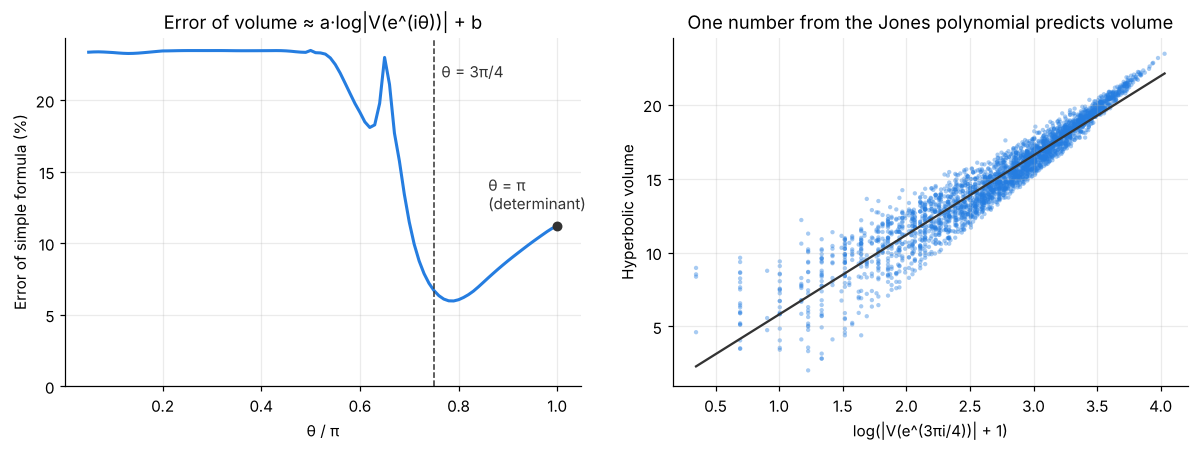

In [6]:
def abs_jones_at_angle(theta):
    t = np.exp(1j * theta)
    return np.array([abs(sum(ci * t ** (lo + i) for i, ci in enumerate(v)))
                     for v, lo in zip(coeffs, df["jones_min_degree"])])

thetas = np.linspace(0.05, 1.0, 96)            # theta / pi
scan = []
for k in thetas:
    feat = np.log(abs_jones_at_angle(k * np.pi) + 1).reshape(-1, 1)
    scan.append(evaluate(LinearRegression(), feat)[1])
scan = np.array(scan)
best_k = thetas[scan.argmin()]
print(f"Best angle: theta = {best_k:.2f} * pi, error {scan.min():.1%}")
print(f"At theta = 0.75 * pi (that is, 3*pi/4):  error {scan[np.argmin(abs(thetas - 0.75))]:.1%}")
print(f"At theta = pi (the determinant):         error {scan[-1]:.1%}")

feat_34 = np.log(abs_jones_at_angle(0.75 * np.pi) + 1).reshape(-1, 1)
fit = LinearRegression().fit(feat_34, y)
print(f"Fitted formula: volume ≈ {fit.coef_[0]:.2f} · log(|V(e^(3πi/4))| + 1) + ({fit.intercept_:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.plot(thetas, scan * 100, color=ALT, lw=2)
ax.axvline(0.75, color=INK, lw=1, ls="--"); ax.text(0.765, scan.max() * 100 * 0.92, "θ = 3π/4", color=INK)
ax.scatter([1.0], [scan[-1] * 100], color=INK, zorder=3, s=30); ax.text(0.86, scan[-1] * 100 + 1.2, "θ = π\n(determinant)", color=INK)
ax.set(xlabel="θ / π", ylabel="Error of simple formula (%)", title="Error of volume ≈ a·log|V(e^(iθ))| + b",
       ylim=(0, None))
ax = axes[1]
ax.scatter(feat_34[:, 0], y, s=8, alpha=0.4, color=ALT, edgecolor="none")
xx = np.linspace(feat_34.min(), feat_34.max(), 50)
ax.plot(xx, fit.predict(xx.reshape(-1, 1)), color=INK, lw=1.5)
ax.set(xlabel="log(|V(e^(3πi/4))| + 1)", ylabel="Hyperbolic volume", title="One number from the Jones polynomial predicts volume")
plt.tight_layout(); plt.savefig("figures/p2_angle_scan.png", dpi=150); plt.show()

## Findings

1. **A neural network predicts hyperbolic volume from the Jones polynomial** with the cross-validated error printed in
   Section 3, well below both linear baselines. This reproduces the result of Jejjala, Kar and Parrikar on knots up to 12 crossings.
2. **It works for non-alternating knots too**, where the determinant alone is a weaker predictor (Project 1).
3. **It needs fairly little data**: trained on about 10% of the knots (roughly 300), it already beats the best linear baseline. With only 5% it does worse than the baseline.
4. **A one-number formula comes close.** Scanning evaluation points t = e^(iθ), the best simple formula appears at
   θ ≈ 0.79π, close to 3π/4, and roughly halves the error of the determinant (θ = π). This is consistent with Craven,
   Jejjala and Kar (2021), who extracted a similar formula at e^(3πi/4) by analyzing a trained network.

**Limitations.** Only 2,970 knots with up to 12 crossings; published work uses far larger tables. The angle scan uses a
single linear model, so a better formula may exist. Different random seeds change the network error slightly.

**Questions I would like to explore.** Why 3π/4, and does the best angle drift as crossing number grows? Do colored Jones
polynomials, which appear in the volume conjecture, predict volume better than the Jones polynomial?

**References.**
V. Jejjala, A. Kar, O. Parrikar, *Deep learning the hyperbolic volume of a knot*, Physics Letters B 799 (2019).
J. Craven, V. Jejjala, A. Kar, *Disentangling a deep learned volume formula*, JHEP (2021).
C. Livingston and A. H. Moore, *KnotInfo: Table of Knot Invariants*.